In [6]:
%pip install kagglehub

import kagglehub

# Download latest version
path = kagglehub.dataset_download("mczielinski/bitcoin-historical-data")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Path to dataset files: C:\Users\kiyul\.cache\kagglehub\datasets\mczielinski\bitcoin-historical-data\versions\767


In [7]:
import pandas as pd
from pathlib import Path

csv_file = next(Path(path).rglob("*.csv"))
df = pd.read_csv(csv_file)

df.head()

,Timestamp,Open,High,Low,Close,Volume
0,1325376060,4.58,4.58,4.58,4.58,0.0
1,1325376120,4.58,4.58,4.58,4.58,0.0
2,1325376180,4.58,4.58,4.58,4.58,0.0
3,1325376240,4.58,4.58,4.58,4.58,0.0
4,1325376300,4.58,4.58,4.58,4.58,0.0


In [8]:
import matplotlib.pyplot as plt

# 숫자로 저장된 시간을 날짜로 변환
df["Date"] = pd.to_datetime(df["Timestamp"], unit="s")

# 날짜별 종가와 거래량 정리
daily = (
    df.set_index("Date")
      .sort_index()
      .resample("D")
      .agg({"Close": "last", "Volume": "sum"})
      .dropna(subset=["Close"])
)

# 데이터에 들어 있는 마지막 날짜 기준 최근 90일
recent = daily.tail(90)

recent.head()

,Close,Volume
Date,,
2026-08-04,64056.48,1012.024812
2026-08-05,64600.22,1116.546145
2026-08-06,64255.55,1131.903515
2026-08-07,64877.77,1964.135392
2026-08-08,64908.72,520.804562


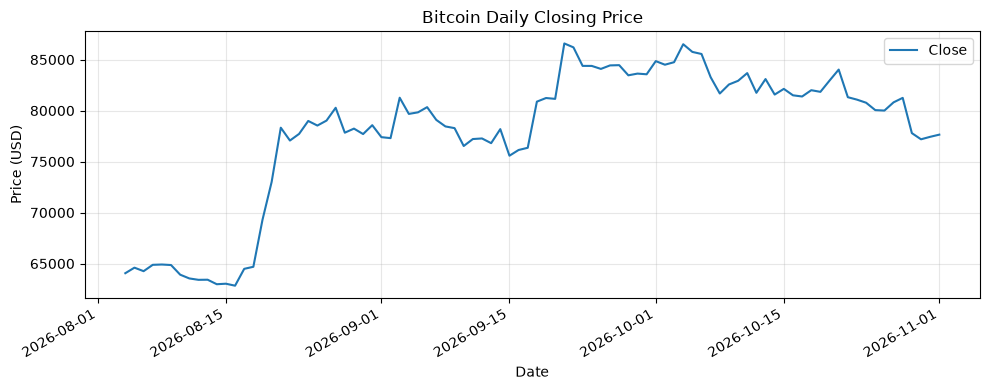

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(recent.index, recent["Close"], label="Close")
ax.set_title("Bitcoin Daily Closing Price")
ax.set_xlabel("Date")
ax.set_ylabel("Price (USD)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

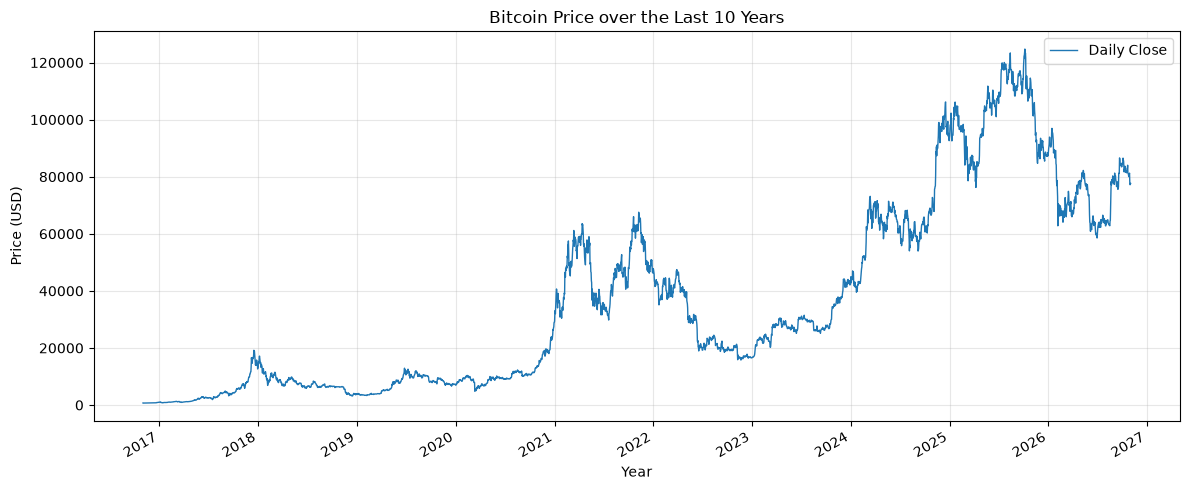

Period: 2016-11-01 to 2026-11-01


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 데이터의 마지막 날짜를 기준으로 10년 전부터 선택
end_date = daily.index.max()
start_date = end_date - pd.DateOffset(years=10)
ten_years = daily.loc[start_date:end_date]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ten_years.index, ten_years["Close"], label="Daily Close", linewidth=1)
ax.set_title("Bitcoin Price over the Last 10 Years")
ax.set_xlabel("Year")
ax.set_ylabel("Price (USD)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(f"Period: {ten_years.index.min():%Y-%m-%d} to {ten_years.index.max():%Y-%m-%d}")


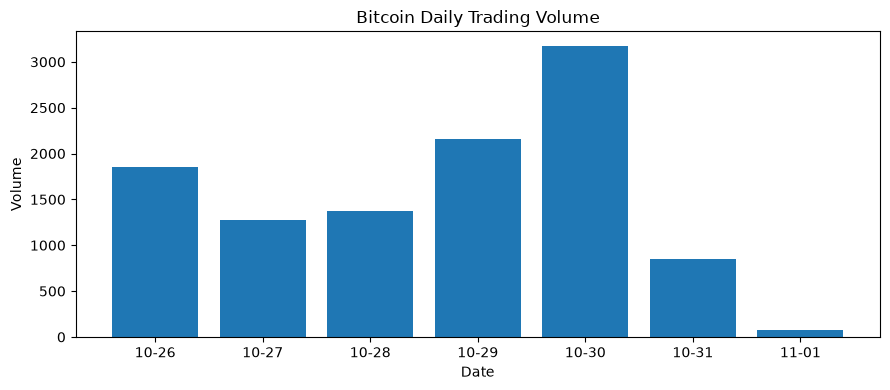

In [11]:
last7 = daily.tail(7)

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(last7.index.strftime("%m-%d"), last7["Volume"])
ax.set_title("Bitcoin Daily Trading Volume")
ax.set_xlabel("Date")
ax.set_ylabel("Volume")

plt.tight_layout()
plt.show()

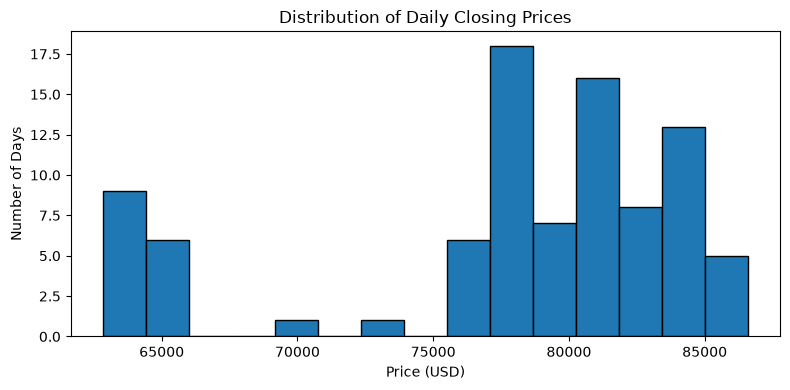

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(recent["Close"], bins=15, edgecolor="black")
ax.set_title("Distribution of Daily Closing Prices")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Number of Days")

plt.tight_layout()
plt.show()

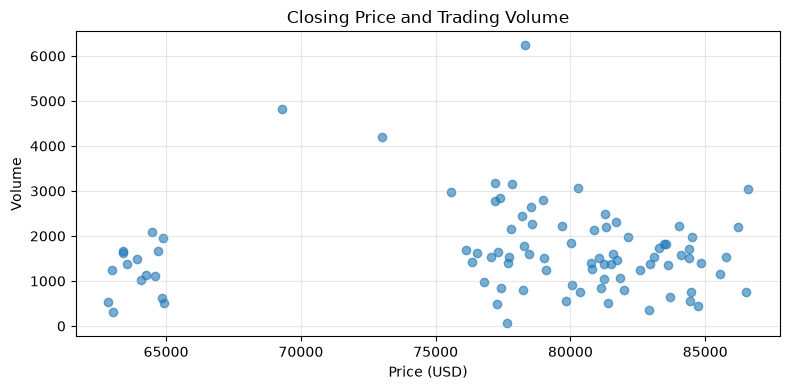

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    recent["Close"],
    recent["Volume"],
    alpha=0.6
)
ax.set_title("Closing Price and Trading Volume")
ax.set_xlabel("Price (USD)")
ax.set_ylabel("Volume")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

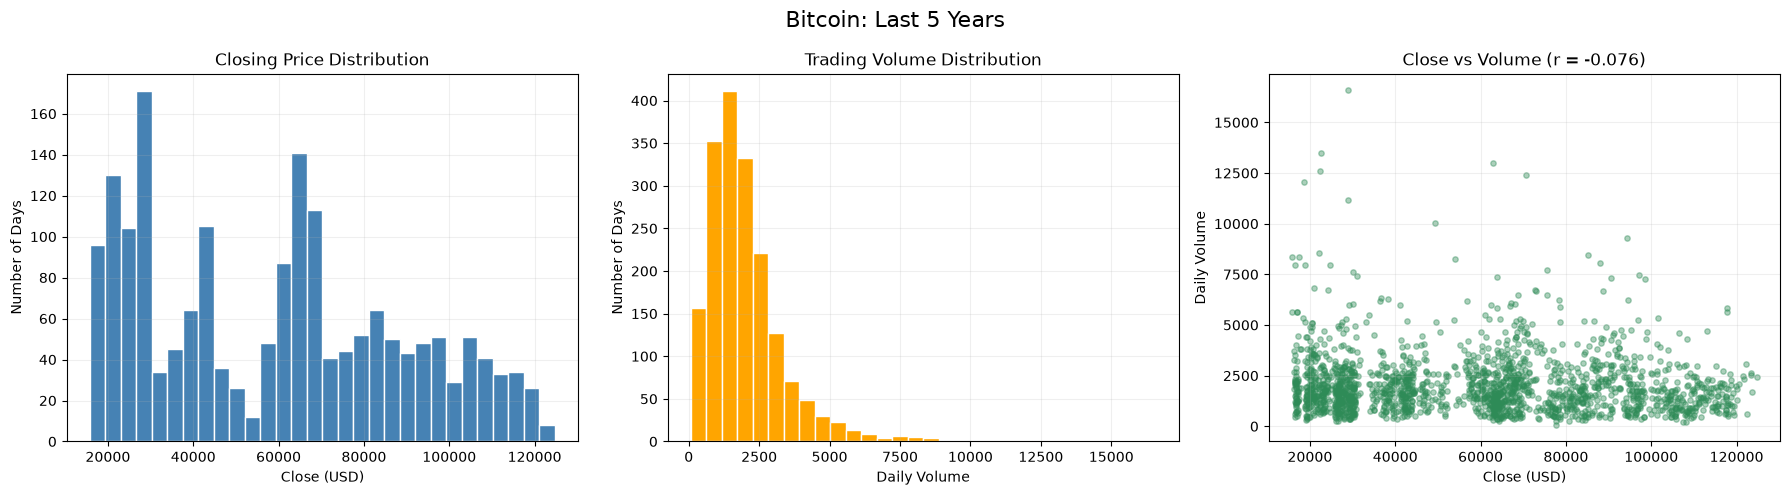

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터의 마지막 날짜 기준 최근 5년
end_date = daily.index.max()
start_date = end_date - pd.DateOffset(years=5)

five_years = daily.loc[start_date:end_date, ["Close", "Volume"]].dropna()

# 일별 종가와 일별 거래량의 상관계수
correlation = five_years["Close"].corr(five_years["Volume"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. 종가 분포
axes[0].hist(
    five_years["Close"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)
axes[0].set_title("Closing Price Distribution")
axes[0].set_xlabel("Close (USD)")
axes[0].set_ylabel("Number of Days")

# 2. 거래량 분포
axes[1].hist(
    five_years["Volume"],
    bins=30,
    color="orange",
    edgecolor="white"
)
axes[1].set_title("Trading Volume Distribution")
axes[1].set_xlabel("Daily Volume")
axes[1].set_ylabel("Number of Days")

# 3. 종가와 거래량의 관계
axes[2].scatter(
    five_years["Close"],
    five_years["Volume"],
    alpha=0.4,
    s=15,
    color="seagreen"
)
axes[2].set_title(f"Close vs Volume (r = {correlation:.3f})")
axes[2].set_xlabel("Close (USD)")
axes[2].set_ylabel("Daily Volume")

for ax in axes:
    ax.grid(alpha=0.2)

fig.suptitle("Bitcoin: Last 5 Years", fontsize=16)
plt.tight_layout()
plt.show()

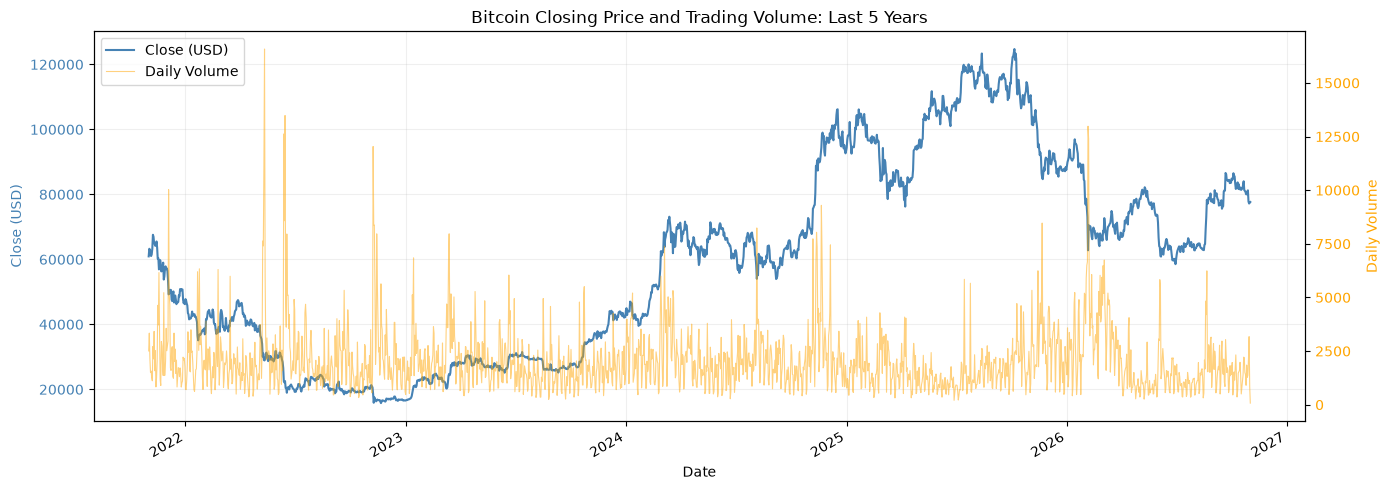

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터의 마지막 날짜 기준 최근 5년
end_date = daily.index.max()
start_date = end_date - pd.DateOffset(years=5)
five_years = daily.loc[start_date:end_date]

fig, ax1 = plt.subplots(figsize=(14, 5))

# 왼쪽 y축: 종가
line1 = ax1.plot(
    five_years.index,
    five_years["Close"],
    color="steelblue",
    label="Close (USD)"
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Close (USD)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

# 오른쪽 y축: 거래량
ax2 = ax1.twinx()

line2 = ax2.plot(
    five_years.index,
    five_years["Volume"],
    color="orange",
    alpha=0.5,
    linewidth=0.8,
    label="Daily Volume"
)
ax2.set_ylabel("Daily Volume", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")

# 두 그래프의 범례 합치기
lines = line1 + line2
ax1.legend(lines, [line.get_label() for line in lines], loc="upper left")

ax1.set_title("Bitcoin Closing Price and Trading Volume: Last 5 Years")
ax1.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

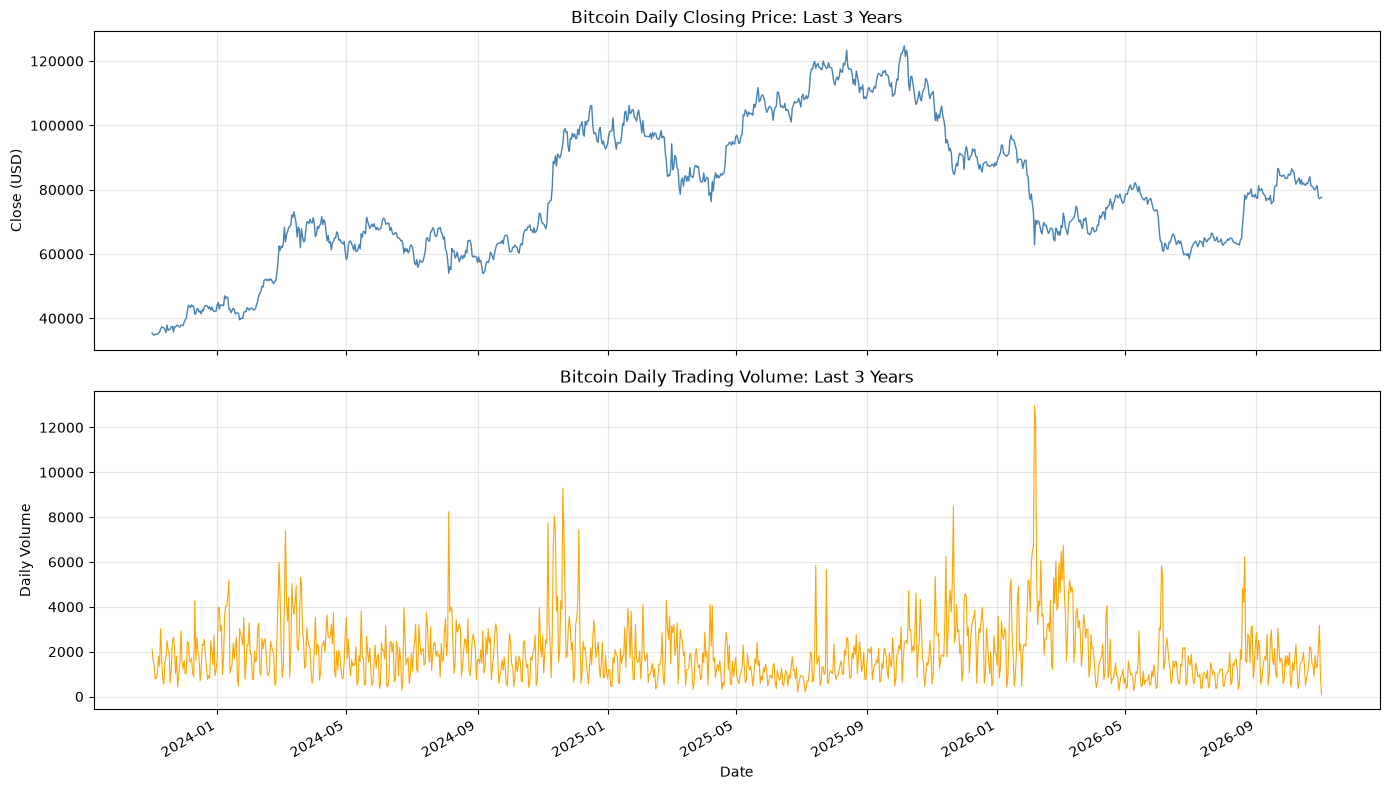

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 데이터의 마지막 날짜 기준 최근 3년
end_date = daily.index.max()
start_date = end_date - pd.DateOffset(years=3)
three_years = daily.loc[start_date:end_date]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# 1. 일별 종가
axes[0].plot(
    three_years.index,
    three_years["Close"],
    color="steelblue",
    linewidth=1
)
axes[0].set_title("Bitcoin Daily Closing Price: Last 3 Years")
axes[0].set_ylabel("Close (USD)")
axes[0].grid(alpha=0.3)

# 2. 일별 거래량
axes[1].plot(
    three_years.index,
    three_years["Volume"],
    color="orange",
    linewidth=0.8
)
axes[1].set_title("Bitcoin Daily Trading Volume: Last 3 Years")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Daily Volume")
axes[1].grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

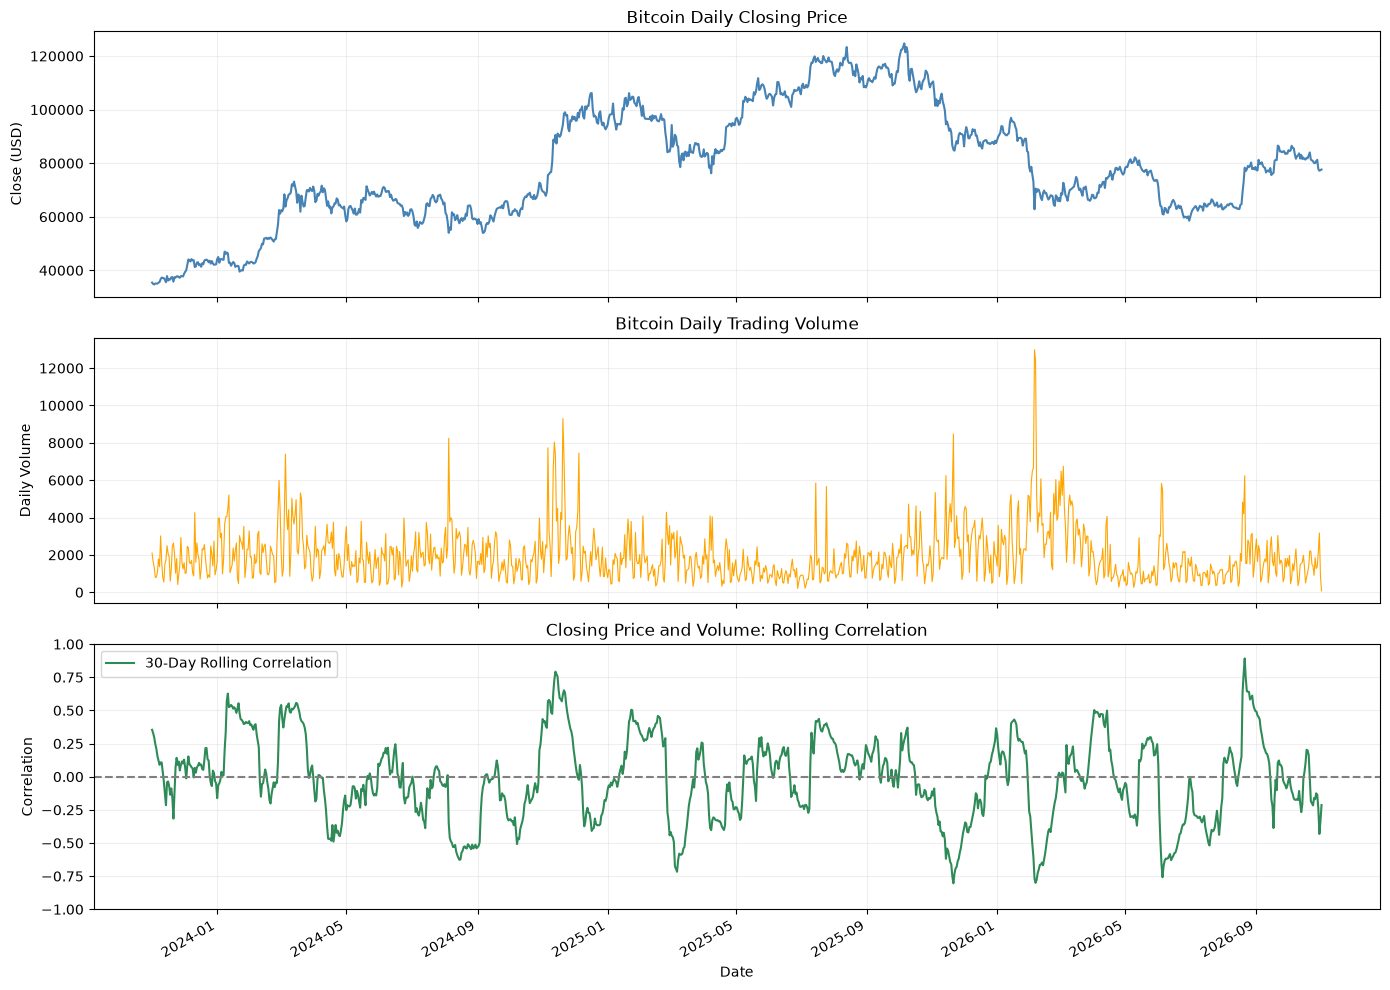

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# 날짜순으로 정리한 일별 데이터
data = daily[["Close", "Volume"]].sort_index()

# 최근 30일의 종가와 거래량으로 상관계수 계산
rolling_corr = (
    data["Close"]
    .rolling("30D", min_periods=20)
    .corr(data["Volume"])
)

# 그래프에 표시할 최근 3년
end_date = data.index.max()
start_date = end_date - pd.DateOffset(years=3)

three_years = data.loc[start_date:end_date]
corr_three_years = rolling_corr.loc[start_date:end_date]

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# 1. 종가
axes[0].plot(
    three_years.index, three_years["Close"],
    color="steelblue"
)
axes[0].set_title("Bitcoin Daily Closing Price")
axes[0].set_ylabel("Close (USD)")

# 2. 거래량
axes[1].plot(
    three_years.index, three_years["Volume"],
    color="orange", linewidth=0.8
)
axes[1].set_title("Bitcoin Daily Trading Volume")
axes[1].set_ylabel("Daily Volume")

# 3. 최근 30일 이동 상관계수
axes[2].plot(
    corr_three_years.index, corr_three_years,
    color="seagreen", label="30-Day Rolling Correlation"
)
axes[2].axhline(0, color="gray", linestyle="--")
axes[2].set_ylim(-1, 1)
axes[2].set_title("Closing Price and Volume: Rolling Correlation")
axes[2].set_ylabel("Correlation")
axes[2].set_xlabel("Date")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.2)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

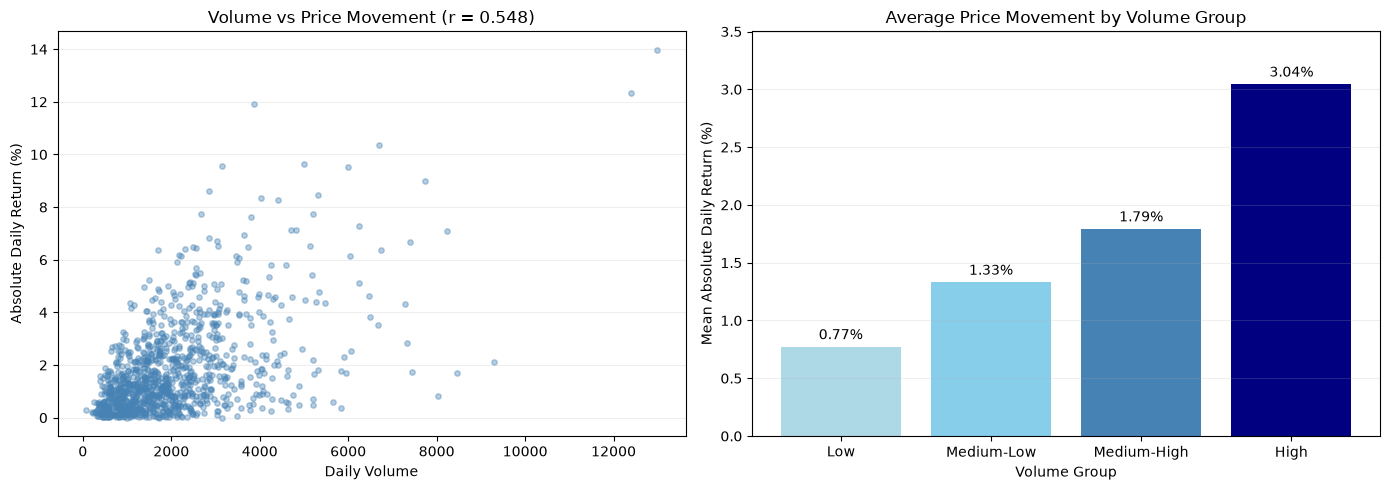

피어슨 상관계수: 0.5477
스피어만 순위 상관계수: 0.4941

거래량 구간별 가격 변동 크기
              count      mean    median
Volume_Group                           
Low             275  0.773391  0.550952
Medium-Low      274  1.330925  1.095982
Medium-High     274  1.792754  1.407433
High            274  3.044977  2.391189


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

data = daily[["Close", "Volume"]].sort_index().copy()

# 전날 대비 종가 변화율과 그 절댓값
data["Return"] = data["Close"].pct_change(fill_method=None) * 100
data["Abs_Return"] = data["Return"].abs()

# 데이터 마지막 날짜 기준 최근 3년
end_date = data.index.max()
start_date = end_date - pd.DateOffset(years=3)

analysis = data.loc[start_date:end_date].copy()
analysis = analysis.dropna(subset=["Close", "Volume", "Abs_Return"])
analysis = analysis[analysis["Volume"] > 0]

# 거래량을 기준으로 관측 일수를 비슷하게 4개 구간으로 구분
analysis["Volume_Group"] = pd.qcut(
    analysis["Volume"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

# 구간별 평균 가격 변동 크기
group_mean = (
    analysis.groupby("Volume_Group", observed=True)["Abs_Return"]
    .mean()
)

# 거래량과 가격 변동 크기의 상관계수
pearson = analysis["Volume"].corr(analysis["Abs_Return"])
spearman = (
    analysis["Volume"].rank()
    .corr(analysis["Abs_Return"].rank())
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. 거래량과 가격 변동 크기의 관계
axes[0].scatter(
    analysis["Volume"],
    analysis["Abs_Return"],
    alpha=0.4,
    s=15,
    color="steelblue"
)
axes[0].set_title(f"Volume vs Price Movement (r = {pearson:.3f})")
axes[0].set_xlabel("Daily Volume")
axes[0].set_ylabel("Absolute Daily Return (%)")

# 2. 거래량 구간별 평균 가격 변동 크기
bars = axes[1].bar(
    group_mean.index.astype(str),
    group_mean.values,
    color=["lightblue", "skyblue", "steelblue", "navy"]
)
axes[1].bar_label(bars, fmt="%.2f%%", padding=3)
axes[1].set_title("Average Price Movement by Volume Group")
axes[1].set_xlabel("Volume Group")
axes[1].set_ylabel("Mean Absolute Daily Return (%)")
axes[1].margins(y=0.15)

for ax in axes:
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print(f"피어슨 상관계수: {pearson:.4f}")
print(f"스피어만 순위 상관계수: {spearman:.4f}")

print("\n거래량 구간별 가격 변동 크기")
print(
    analysis.groupby("Volume_Group", observed=True)["Abs_Return"]
    .agg(["count", "mean", "median"])
)